# Лабораторная работа №3. Анализ сетевого трафика

## Часть 1. Классификация сетевого трафика: норма или аномалия?

## Выполнили работу:
### Симахин Степан Андреевич ИНБс-5301-01-00
### Игнатович Вадим Олегович ИНБс-5301-01-00
---

Часть 1: используется малая выборка датасета признаков сетевых атак в подключениях, целью является получение системы детектирования сетевых атак с выводом бинарной оценки вида "нормальный/аномальный трафик"

## Шаг 0. Подключение датасета

Подключение архива с файлами датасета происходит посредством монтирования файла в Google Drive:

In [2]:
# функция для нормального вывода списков:
def to_str(inp, sep=', '):
  #return str(inp)[1:-1]
  return sep.join(str(it) for it in inp)

# подключение архива datasets.zip, который лежит в Google Диск:
#   прямая ссылка на datasets.zip:
#   https://drive.google.com/file/d/1pt9PgKb9ckkTVfx5YhvzmhfOCREtySsk/view?usp=sharing
from google.colab import drive
drive.mount('/content/drive')
!unzip -q "/content/drive/MyDrive/datasets.zip" -d /content/
print('Файл \'datasets.zip\' подключён')

Mounted at /content/drive
Файл 'datasets.zip' подключён


Подключение файлов в архиве датасета:

In [3]:
import os

# Где лежат данные: рядом с блокнотом (локально) или в /content (Colab)
# DATA_DIR = 'datasets' if os.path.isdir('datasets') else '/content/datasets'
DATA_DIR = 'datasets'

for name in ['ids.csv', 'KDDTrain+.csv', 'KDDTest+.csv']:
    path = os.path.join(DATA_DIR, name)
    assert os.path.isfile(path), (
        f'Файл {name} не найден по пути {path}. '
        'В Colab выполните ячейку «Шаг 0», локально — положите папку datasets рядом с блокнотом.')

print('Успешно найденные файлы датасета: {}.'.format(to_str(sorted(os.listdir(DATA_DIR)))))

Успешно найденные файлы датасета: KDDTest+.csv, KDDTrain+.csv, ids.csv.


## Подключение библиотек:

In [4]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report,
                             ConfusionMatrixDisplay)
from matplotlib.colors import LinearSegmentedColormap

print('Библиотеки подключены')

# what is that below?
RANDOM_STATE = 2  # фиксируем, чтобы результаты воспроизводились

Библиотеки подключены


## Шаг 1. Датасет NSL-KDD
<b> NSL-KDD — Network Security Laboratory Knowledge Discovery in Databases set. </b>

Данный датасет является набором признаков сетевого трафика и используется для тестирования систем обнаружения сетевых атак. Является оптимизированной версией датасета KDD'99, используется с 2009 года и до сих пор.

В каждой строке датасета представлены значения 41 признака одной записи трафика (одного сетевого подключения): длительность, протокол, сервис, объём, различные счётчики и доли ошибок. Последний столбец — метка записи (уровень аномальности записи трафика).

В состав датасета входят файлы:
*   Файл `ids.csv` — компактное подмножество NSL-KDD (25192 записи), метки записей которого принимают значения *normal* и *anomaly*;
*   Файл `KDDTrain+.csv` — подмножество для обучения (125973 записи);
*   Файл `KDDTest+.csv` — подмножество для тестирования (22543 записи).

Полное перечисление 41 признака приведено в таблице: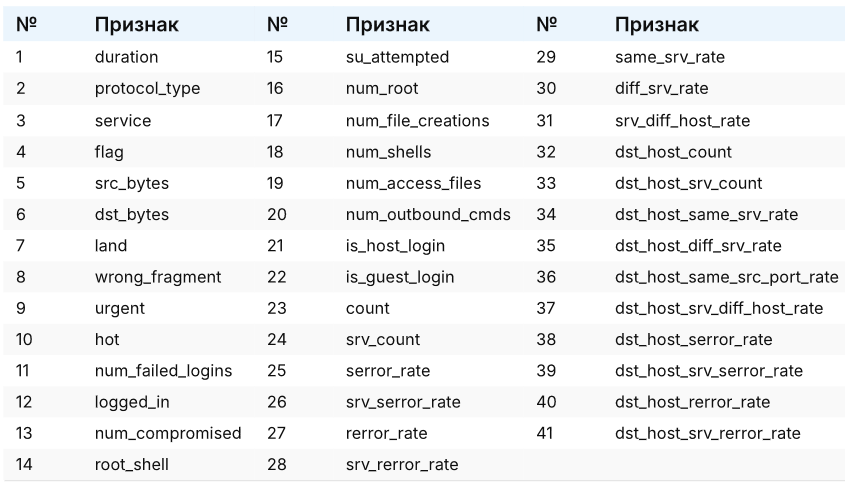

In [5]:
df = pd.read_csv(os.path.join(DATA_DIR, 'ids.csv'))
print('Размеры таблицы датасета \'ids.csv\': ', df.shape, '.', sep='')
print('Первые 5 записей файла \'ids.csv\':')
df.head()

Размеры таблицы датасета 'ids.csv': (25192, 42).
Первые 5 записей файла 'ids.csv':


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


In [6]:
# Пропуски и типы данных
print('Пропущенных значений:', df.isnull().sum().sum())
print()
print(df.dtypes.value_counts().to_frame('число столбцов'))

Пропущенных значений: 0

         число столбцов
int64                23
float64              15
object                4


Вопросы:
1. Какие три признака являются категориальными (строковыми)?
2. Что описывает признак `service`?


Ответы:
<ol start = "1">
  <li>Из 41 признаков (таблица выше) категориальные (принимающие не числовые значения) признаки: </li>
    <ul type="none">
      <li>- protocol_type — протоколы транспортного уровня OSI (tcp, udp, etc.);</li>
      <li>- service — протоколы прикладного уровня OSI (http, ftp, etc.);</li>
      <li>- flag — состояние соединения (SF, S0, etc.).</li>
    </ul>
  <li>Признак <i>service</i> указывает используемый протокол прикладного уровня модели OSI: http, ftp, smtp, dns и другие. </li>
</ol>

Для ускорения процесса обучения необходимо удалить константные признаки, то есть поля таблицы, значения которых равны для всех записей:

In [7]:
# блок кода поиска константных признаков
#   повторное выполнение блока кода даст пустой вывод,
#   т.к. в следующем блоке кода эти значения удаляются

const_cols = [c for c in df.columns if df[c].nunique() <= 1]
print('Константные признаки:', to_str(const_cols))

Константные признаки: num_outbound_cmds, is_host_login


In [8]:
# блок кода удаления константных признаков
#   повторное выполнение блока кода даст пустой вывод,
#   т.к. в этом блоке кода эти значения удаляются

print('Всего столбцов таблицы:', df.shape[1])
df = df.drop(columns=const_cols)
print('Были удалены признаки:', to_str(const_cols))
print('Осталось столбцов:', df.shape[1])

Всего столбцов таблицы: 42
Были удалены признаки: num_outbound_cmds, is_host_login
Осталось столбцов: 40


Для анализа имеющегося датасета формируется статистика распределения соединений по классам: нормальный и аномальный:

Статистика по классам:
	- normal:	13449 записей;
	- anomaly:	11743 записей.

Распределение по классам:
	- normal:	53.4%;
	- anomaly:	46.6%.

График распределения записей датасета по классам:



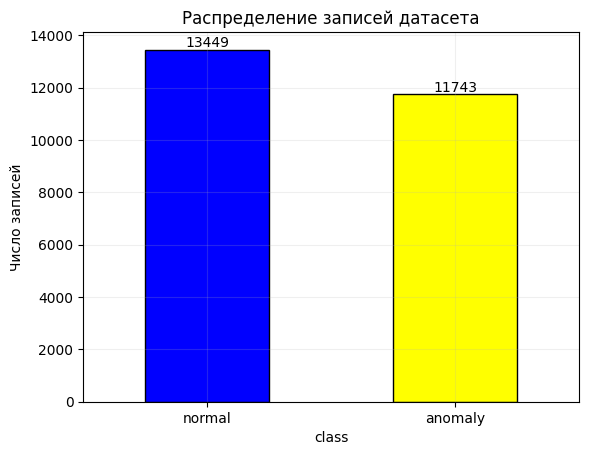

In [9]:
counts = df['class'].value_counts()
print('Статистика по классам:')
print('\t- normal:\t{:} записей;'.format(counts['normal']))
print('\t- anomaly:\t{:} записей.'.format(counts['anomaly']))
print('\nРаспределение по классам:')
print('\t- normal:\t{:.1%};'.format(counts['normal'] / len(df)))
print('\t- anomaly:\t{:.1%}.'.format(counts['anomaly'] / len(df)))

print('\nГрафик распределения записей датасета по классам:\n')
gr2 = counts.plot.bar(color=['blue', 'yellow'], edgecolor='black')
gr2.bar_label(gr2.containers[0], fmt='{:.0f}', fontsize=10)
plt.title('Распределение записей датасета')
plt.ylabel('Число записей')
plt.xticks(rotation=0)
plt.grid(alpha=0.2)
plt.show()

Полученное распределение (53 к 47 нормального трафика к аномальному) является нетипичным для реального трафика — следствие искусственности и идеальности датасета для обучения систем обнаружения вторжений.

## Шаг 2. Предобработка данных

Три операции:

1. **Разделение на train/test** — деление датасета 70 к 30 со стратификацией (`stratify=y`) для сохранения пропорций классов в обеих частях.
2. **Кодирование категориальных признаков** — использование `OrdinalEncoder` для замены строковый категорий на их номера, так как алгоритмы sklearn используют только числовые значения. Параметр `handle_unknown='use_encoded_value'` нужен для избежания в случаях наличия категорий, который есть в датасете тестирования, но не в датасете обучения.
3. **Масштабирование числовых признаков** — использование `MinMaxScaler` для нормализации чисел до диапазона [0, 1] в целях уравнения влияния признаков по численной форме.
<br>
<b>Операция 1. Разделение датасета на train/test: <b>

In [10]:
X = df.drop(columns=['class'])
y = df['class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=RANDOM_STATE, stratify=y)

print(f'train: {X_train.shape[0]} соединений, test: {X_test.shape[0]} соединений')
print('Доля anomaly: train {:.1%}, test {:.1%}'.format(
    (y_train == 'anomaly').mean(), (y_test == 'anomaly').mean()))

train: 17634 соединений, test: 7558 соединений
Доля anomaly: train 46.6%, test 46.6%


Доля аномального трафика в train и test равна 46.6%.
</br></br>
<b>Операции 2 и 3. Кодирование категориальных признаков и масштабирование числовых признаков: </b>


In [11]:
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
num_cols = X.select_dtypes(include='number').columns.tolist()

print('Признаки до данных операций:\n\t- категориальные: {};'.format(str(cat_cols)[1:-1]))
print('\t- числовые: {}, etc. (всего {} признаков).'.format(to_str(num_cols[:5]), len(num_cols)))

# создание DataFrame, который хранит кодированные и масштабированные значения:
preprocess = ColumnTransformer ([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
    ('num', MinMaxScaler(), num_cols),
])

print('\nПервые 5 строк таблицы \'train\' датасета после операций:')
example = pd.DataFrame(preprocess.fit_transform(X_train), columns=cat_cols + num_cols)
example.head(5)

Признаки до данных операций:
	- категориальные: 'protocol_type', 'service', 'flag';
	- числовые: duration, src_bytes, dst_bytes, land, wrong_fragment, etc. (всего 36 признаков).

Первые 5 строк таблицы 'train' датасета после операций:


,protocol_type,service,flag,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,1.0,22.0,9.0,0.0,6.811470e-07,0.000225,0.0,0.0,0.0,0.0,...,0.133858,1.000000,1.00,0.00,0.03,0.02,0.00,0.0,0.00,0.0
1,2.0,11.0,9.0,0.0,1.205106e-07,0.000009,0.0,0.0,0.0,0.0,...,1.000000,1.000000,1.00,0.00,0.01,0.00,0.00,0.0,0.00,0.0
2,1.0,45.0,1.0,0.0,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,...,1.000000,0.031496,0.04,0.09,0.00,0.00,0.00,0.0,1.00,1.0
3,1.0,43.0,9.0,0.0,9.955225e-08,0.000025,0.0,0.0,0.0,0.0,...,0.342520,0.015748,0.02,0.10,0.01,0.40,0.01,0.0,0.01,0.0
4,1.0,15.0,5.0,0.0,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,...,1.000000,0.090551,0.09,0.05,0.00,0.00,1.00,1.0,0.00,0.0


В итоге значениям столбцов, в которых хранились не численные значения, были присвоены коды в виде порядковых номеров их появления в датасете, а численные значения были нормированы до отрезка [0,1], однако полученные кодированные значения остались ненормированными, $\color{indianred}{\text{что нарушает логику данного этапа}}$ и может приводить к ухудшению результатов.

## Шаг 3. Базовая модель: наивный Байес

В качестве простой модели используется модель наивного Байеса, которая основана на теореме Байеса.

Данный метод раскладывает вероятность класса (нормальный/аномальный трафик) при данных признаках по теореме Байеса посредством перемножения вероятностей класса (правдоподобий) при каждом признаке.

Модель называется базовой из-за линейного (независимого) умножения вероятностей класса при каждом признаке, т.е. с допущением их некоррелированности, однако при атаках и их отсутствии признаки обычно взаимосвязаны.

Данная модель работает как baseline (базовая, опорная) модель, так как является крайне простой и не учитывает корреляции, но позволяет оценить класс записи.
<br><br>
Теорема (формула) Байеса приведена на рисунке:

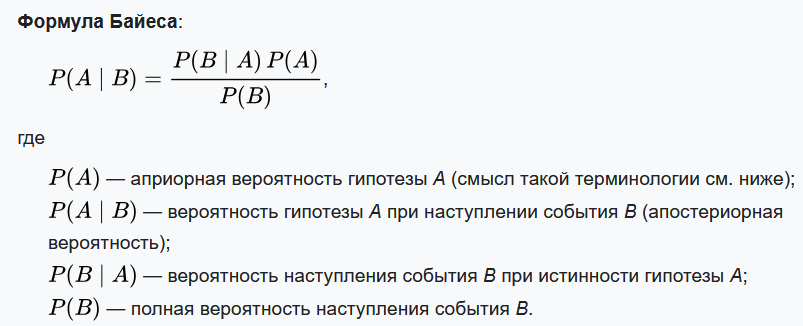

Реализация модели наивного Байеса:

In [12]:
model_nb = make_pipeline(preprocess, GaussianNB())

t0 = time.time()
model_nb.fit(X_train, y_train)
print(f'Время обучения: {time.time() - t0:.2f} с')

y_pred = model_nb.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.3f}')
print('\nПолученные в результате использования модели Байеса характеристики:\n')
print(classification_report(y_test, y_pred, digits=3))

Время обучения: 0.10 с
Accuracy: 0.892

Полученные в результате использования модели Байеса характеристики:

              precision    recall  f1-score   support

     anomaly      0.868     0.906     0.887      3523
      normal      0.915     0.880     0.897      4035

    accuracy                          0.892      7558
   macro avg      0.892     0.893     0.892      7558
weighted avg      0.893     0.892     0.892      7558



В полученной матрице:
* precision – доля TP от всех P; чем ниже, тем больше ложных срабатываний;
* recall – доля TP от всех истинно P; чем выше, тем больше атак отлавливается;
* f1-score – гармоническое среднее этих двух параметров; общая оценка;
* support – вес класса; отображает число кейсов каждого класса в test-выборке.



Полученная в результате использования модели Байеса матрица ошибок в виде рисунка:



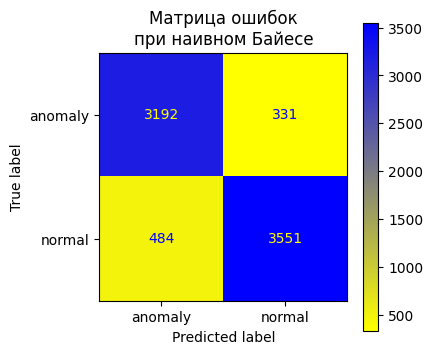

In [13]:
fig, ax = plt.subplots(figsize=(4, 4))
custom_cmap = LinearSegmentedColormap.from_list("yellow_blue", ["yellow", "blue"])
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap=custom_cmap)
plt.title('Матрица ошибок\nпри наивном Байесе')
print('Полученная в результате использования модели Байеса матрица ошибок в виде рисунка:\n')
plt.show()

Вопросы:
1. Какая ошибка для IDS неприятнее — пропустить атаку (FN) или поднять ложную тревогу на нормальное соединение (FP)?
2. Посмотрите на матрицу: каких ошибок у наивного Байеса больше?

Ответы:
1. Ошибка FN (false negative, пропушенная атака) для системы детектирования атак обычно критичнее, так как реализованная и незамечанная атака способна нанести ущерб, тогда при FP (false positive, ложное детектирование) будут затрачены лишние ресурсы без дополнительного вреда системе.
2. При реализации наивного Байеса большего всего ошибок оказалось при FP (484 ошибки), тогда как при FN оказалось на 32% процента меньше ложных срабатываний (331 ошибка).

## Шаг 4. Решающее дерево (CART) и подбор глубины

Решающие деревья (Classification and Regression Trees) относятся к жадным алгоритмам.

Жадные алгоритмы: на каждом шаге ищется локальный оптимальный выбор без зависимости от предыдущих и последующих выборов; полученная последовательность ожидается оптимальной, так как на всех шагах принимались оптимальные выборы.

Решающее дерево строится сверху вниз, при этим каждый внутренний узел дерева является является проверкой одного параметра с заданным порогом, а каждый внешний узел (лист) хранит предсказанный класс.

При обучении алгоритм проходит дерево только один раз, поэтому изменение решения в одном узле при последующих решениях в других узлах не происходит, то есть алгоритм не способен фиксировать взаимосвязи (корреляции) параметров.

Данный алгоритм склонен к переобучению, если не ограничивать размер дерева, так как в таком случае каждая отдельная запись датасета сформирует уникальный лист дерева, и в итоге на тренировочном датасете будет 100% accuracy. С учётом наличия новых атак в `KDDTest+` точность метода при неограниченном дереве ожидается крайне низкой.
<br><br>
Для ограничения размера дерева устанавливается значение параметра `max_depth`, который отвечает за максимальное количество узлов дерева.

Для определения значения параметра `max_depth` может использоваться инструмент `GridSearchCV` (Grid Search with Search Validation), который автоматически перебирает все комбинации указанных гиперпараметров (параметры работы алгоритма: max_depth, min_samples_leaf, criterion, ...) с целью найти такую комбинацию, которая даст лучший результат при кросс-валидации.

Кросс-валидация: из каждой группы по N выборок поочерёдно отбираются M выборок для обучения и (N-M) выборок для тестирования, при этом на каждом следующем шаге берутся разные комбинации распределения выборок на обучение и тестирования из этой выборк. В итоге такой кросс-валидации системе обучается с постоянным обучением на "новых" данных с использованием только датасета для обучения.
<br><br>
В качестве гиперпараметров для `GridSearchCV` задаётся сетка. В данной работе сетка имеет высоту 1 и ширину 12, формируя по заданному параметру `max_depth` 1*12=12 возможных моделей и отбирая в итоге лучшую.
<br><br>
Реализация решающего дерева:

In [14]:
# WARNING: takes 0.5 minutes to run
max_depth_list = [2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20, None]

grid_tree = GridSearchCV(
    make_pipeline(preprocess, DecisionTreeClassifier(random_state=RANDOM_STATE)),
    {'decisiontreeclassifier__max_depth': max_depth_list},
    cv=5, n_jobs=-1, scoring='accuracy')

t0 = time.time()
grid_tree.fit(X_train, y_train)
print(f'Размер сетки для GridSearchCV = {len(max_depth_list)}')
print(f'Число отбираемых моделей равно 1x{len(max_depth_list)}={1*len(max_depth_list)}')
print(f'Время моделирования всех моделей: {time.time() - t0:.1f} с')
print(f'Параметры лучшей модели:\n\t- \'max_depth\' = {grid_tree.best_params_.get('decisiontreeclassifier__max_depth')}.')
print(f'Accuracy на кросс-валидации: {grid_tree.best_score_:.4f}')

Размер сетки для GridSearchCV = 12
Число отбираемых моделей равно 1x12=12
Время моделирования всех моделей: 21.9 с
Параметры лучшей модели:
	- 'max_depth' = 15.
Accuracy на кросс-валидации: 0.9946


Заданная сетка задаёт минимальный размер крайних узлов дерева, поэтому принимается значение по умолчанию (`min_saples_leaf=1`), что может приводить к запоминанию не общих правил, а крайних значений, то есть к запоминанию шумов.

Ограничение параметра `max_depth` не способно полностью устранить данную проблему, так как в датасете присутствует рецессивность случаев для классов R2L и U2R, как было выяснено ранее, а значит, для этих классов число случаев может оказаться соразмерно размеру дерева, что приведён к полному запоминанию именно этих случаев системой и сделает систему неспособной адекватно оценивать трафик с такими атаками.
<br><br>
Установление параметра `scoring='accuracy'` приводит к отбору моделей именно по accuracy, что приводит к получению максимально верно угадывающей системы, однако при данном значении параметра модель будет отлично оценивать классы, которых было большинство в датасете обучения, и будет плохо оценивать классы, которых было незначительно в датасете.

Для борьбы с данной проблемой используется обычно значение `scoring='f1_macro'`, при котором классы учитываются поровну, а значит, вероятность пропущенной атаки ожидается более низкой.
<br><br>
Код оценки полученной модели на тестовой выборке:

Используется модель со значением 'max_depth' = 15

Полученное значение accuracy на датасете тестирования: 0.996
Полученные характеристики:

              precision    recall  f1-score   support

     anomaly      0.995     0.995     0.995      3523
      normal      0.996     0.996     0.996      4035

    accuracy                          0.996      7558
   macro avg      0.995     0.995     0.995      7558
weighted avg      0.996     0.996     0.996      7558


Получаемая точность (accuracy) при разных значениях параметра 'max_depth':



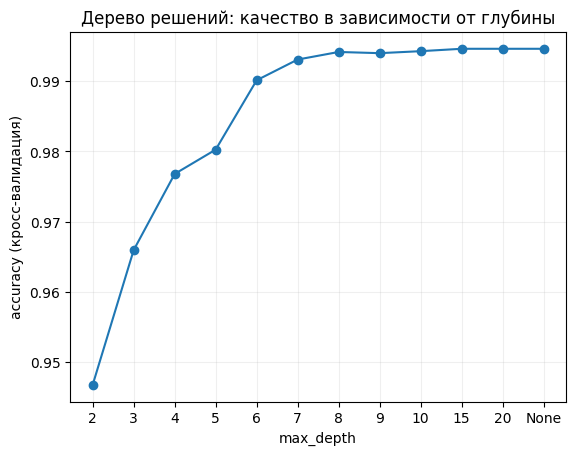

In [15]:
print(f'Используется модель со значением \'max_depth\' = {grid_tree.best_params_.get('decisiontreeclassifier__max_depth')}')
model_tree = grid_tree.best_estimator_
y_pred = model_tree.predict(X_test)

print(f'\nПолученное значение accuracy на датасете тестирования: {accuracy_score(y_test, y_pred):.3f}')
print('Полученные характеристики:\n')
print(classification_report(y_test, y_pred, digits=3))

depths = [str(p['decisiontreeclassifier__max_depth']) for p in grid_tree.cv_results_['params']]
scores = grid_tree.cv_results_['mean_test_score']

print('\nПолучаемая точность (accuracy) при разных значениях параметра \'max_depth\':\n')
plt.plot(range(len(depths)), scores, marker='o')
plt.xticks(range(len(depths)), depths)
plt.xlabel('max_depth')
plt.ylabel('accuracy (кросс-валидация)')
plt.title('Дерево решений: качество в зависимости от глубины')
plt.grid(alpha=0.2)
plt.show()

По графику видно, что при значении параметра `max_depth` от 10 и выше формируются максимальные значения accuracy.

Получение конкретных значений в этих узлах для сравнения значений:

In [16]:
print('max_depth | \t' + to_str(depths[-4:], sep='\t\t\t'))
print('accuracy  | \t' + to_str(scores[-4:], sep='\t'))

max_depth | 	10			15			20			None
accuracy  | 	0.99427247965255	0.9946126478164314	0.9946126478164314	0.9946126478164314


По полученным значениям можно заметить, что при `max_depth` от 15 и выше значения `accuracy` одинаковы, а значит, достигнута идеальная точность.

С учётом достижения идельной точности алгоритм выбрал первое лучшее значение, поэтому `max_depth` = 15.

Вопросы:
1. Почему кривая качества после некоторой глубины выходит на плато?
2. Что было бы с accuracy на *тренировочной* выборке при `max_depth=None`?

Ответы (краткие с учётом всего отмеченного выше):
1. Происходит перенасыщение, дерево начинает запоминать частные случаи
2. При неограниченном размере дерево запоминает все частные случаи.

## Шаг 5. k ближайших соседей (k-NN) и подбор k

Алгоритм 'k-NN' (k-Nearest Neignbors) относят к "ленивым" алгоритмам, так как принципиального обучения не происходит: алгоритм хранит матрицу оценки, полученную в процессе запоминания при обучении, с которой сравнивает входящие значения при тестировании. При этом не происходит никаких оптимизаций или расчётов, значения датасета обучения просто сохраняются.

Данный алгоритм является простым в обучении, однако требует относительно много памяти, так как признаки всех записей датасета необходимо хранить в исходном виде, а также при большом числе параметров (больше 15-20) процесс оценки становится медленным, особенно учитывая необходимость обработки входящего значения относительно всех записей обучающего датасета.

Для оценки нового значения алгоритм находит расстояния до всех точек (каждая точка является одной выборкой датасета обучения, то есть число точек равно числу выборок в датасете, а это 17634 точек), формируя вектор расстояний. Далее вектор сортируется по возрастанию, находится k наименьших расстояний, по которым находятся k ближайших соседей. Для получения оценки необходимо агрегировать эти k значений, обычно посредством умножения меток этих k соседей на их веса, которые обратно пропорциональны векторам расстояниям. В итоге отбирается предсказание с наибольшим значением, что и означает поиск ближайшего соседа.
<br><br>
Точность и устойчивость к переобучению модели зависит от числа соседей k: при большом значении система груба, так как граница между решениями размывается, а при малом значении система переобучается и запоминает шум, так как каждый отдельный случай становится отдельным правилом.

Для поиска оптимального значения числа k соседей используется тот же метод кросс-валидации:

In [17]:
# WARNING: takes 0.5 minutes to run
k_list = [1, 3, 5, 7, 9, 11, 15]

grid_knn = GridSearchCV(
    make_pipeline(preprocess, KNeighborsClassifier(n_jobs=-1)),
    {'kneighborsclassifier__n_neighbors': k_list},
    cv=5, n_jobs=-1, scoring='accuracy')

t0 = time.time()
grid_knn.fit(X_train, y_train)
print(f'Время расчёта всех моделей: {time.time() - t0:.1f} с')
print(f'Параметры лучшей модели:\n\t- \'k\' = {grid_knn.best_params_.get('kneighborsclassifier__n_neighbors')}.')
print(f'Значение accuracy на кросс-валидации: {grid_knn.best_score_:.4f}')

model_knn = grid_knn.best_estimator_
y_pred = model_knn.predict(X_test)
print(f'Значение accuracy на датасете для тестирования: {accuracy_score(y_test, y_pred):.3f}')

Время расчёта всех моделей: 16.0 с
Параметры лучшей модели:
	- 'k' = 1.
Значение accuracy на кросс-валидации: 0.9926
Значение accuracy на датасете для тестирования: 0.994


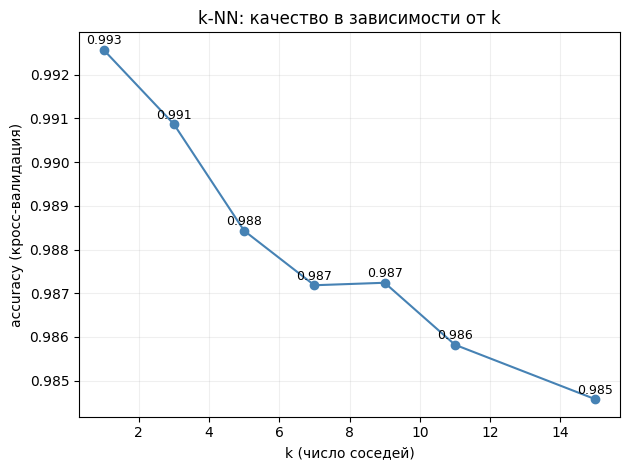

In [18]:
neighbors = [p['kneighborsclassifier__n_neighbors'] for p in grid_knn.cv_results_['params']]
scores = grid_knn.cv_results_['mean_test_score']
plt.plot(neighbors, scores, marker='o', color='steelblue')
for x, y in zip(neighbors, scores):
    plt.annotate(f'{y:.3f}', (x, y), textcoords='offset points', xytext=(0, 4), ha='center', fontsize=9)

plt.xlabel('k (число соседей)')
plt.ylabel('accuracy (кросс-валидация)')
plt.title('k-NN: качество в зависимости от k')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Шаг 6. Логистическая регрессия

Алгоритм логистической регрессии вместо статистического профилирования классов строит многомерные плоскости, которые разделяют пространство на области классов.

Данный алгоритм является простым в плане разделения, поэтому граничные суперплоскости не могут не быть плоскими.
<br><br>
Реализация логистической регрессии:

In [19]:
model_lr = make_pipeline(preprocess, LogisticRegression(max_iter=9000))

t0 = time.time()
model_lr.fit(X_train, y_train)
print(f'Время обучения: {time.time() - t0:.1f} с')

y_pred = model_lr.predict(X_test)
print(f'Значение accuracy при использовании датасета для тестирования: {accuracy_score(y_test, y_pred):.3f}')
print('\nПолученные характеристики:\n')
print(classification_report(y_test, y_pred, digits=3))

Время обучения: 6.8 с
Значение accuracy при использовании датасета для тестирования: 0.953

Полученные характеристики:

              precision    recall  f1-score   support

     anomaly      0.967     0.932     0.949      3523
      normal      0.942     0.972     0.957      4035

    accuracy                          0.953      7558
   macro avg      0.954     0.952     0.953      7558
weighted avg      0.954     0.953     0.953      7558



## Шаг 7. Сравнение классификаторов и выводы

Для сравнения использованных алгоритмов классификации необходимо собрать результаты работы алгоритмов относительно класса `anomaly`, ведь, как было отмечено ранее, недетектирование атак в трафике критичнее ложного детектирования.
<br><br>
Код сбора результатов работы алгоритмов относительно класса `anomaly`:

In [20]:
models = {'Наивный Байес': model_nb,  'Дерево решений': model_tree,
          'k-NN': model_knn,  'Логистическая регрессия': model_lr}
rows = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    rows[name] = [accuracy_score(y_test, y_pred),
                  precision_score(y_test, y_pred, pos_label='anomaly'),
                  recall_score(y_test, y_pred, pos_label='anomaly'),
                  f1_score(y_test, y_pred, pos_label='anomaly')]

summary = pd.DataFrame(rows,
index=['Accuracy (total)', 'Precision', 'Recall', 'F1']).T
print('Полученные результаты относительно класса \'anomaly\' (кроме первого столбца):\n')
print((summary * 100).round(2).astype(str) + '%')

Полученные результаты относительно класса 'anomaly' (кроме первого столбца):

                        Accuracy (total) Precision  Recall      F1
Наивный Байес                     89.22%    86.83%   90.6%  88.68%
Дерево решений                    99.55%    99.52%  99.52%  99.52%
k-NN                              99.42%    99.66%  99.09%  99.37%
Логистическая регрессия           95.32%    96.67%  93.16%  94.88%


Столбчатые диаграммы сравнения используемых алгоритмов по параметру 'accuracy':



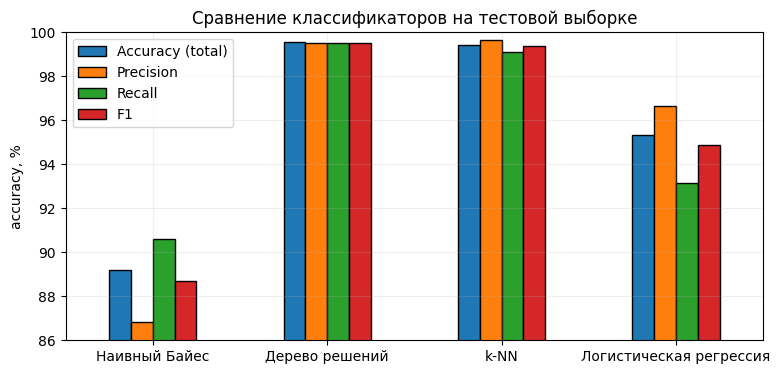

In [21]:
(summary * 100).plot.bar(rot=0, ylim=(86, 100), figsize=(9, 4), edgecolor='black')
plt.ylabel('accuracy, %')
plt.title('Сравнение классификаторов на тестовой выборке')
plt.legend(loc='upper left')
plt.grid(alpha=0.2)
print('Столбчатые диаграммы сравнения используемых алгоритмов по параметру \'accuracy\':\n')
plt.show()

Значения на диапазоне accuracy > 98% на данном графике мало отличимы, поэтому формируется фрагмент данного графика:

Верхний фрагмент столбчатой диаграммы:



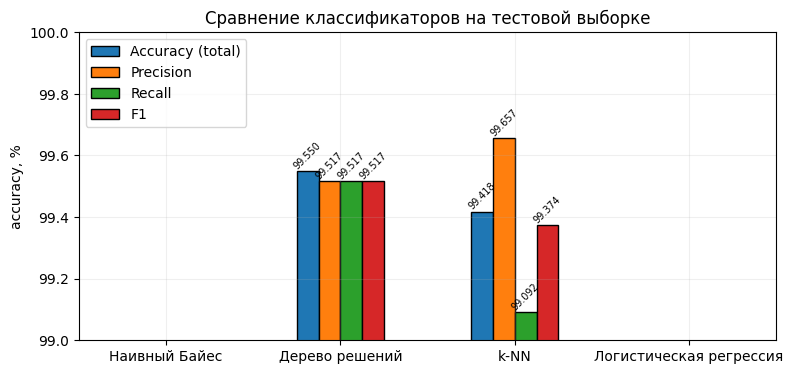

In [22]:
gr3 =(summary * 100).plot.bar(rot=0, ylim=(99, 100), figsize=(9, 4), edgecolor='black')
gr3.bar_label(gr3.containers[0], fmt='{:.3f}', rotation=45, fontsize=7)
gr3.bar_label(gr3.containers[1], fmt='{:.3f}', rotation=45, fontsize=7)
gr3.bar_label(gr3.containers[2], fmt='{:.3f}', rotation=45, fontsize=7)
gr3.bar_label(gr3.containers[3], fmt='{:.3f}', rotation=45, fontsize=7)
plt.ylabel('accuracy, %')
plt.title('Сравнение классификаторов на тестовой выборке')
plt.legend(loc='upper left')
plt.grid(alpha=0.2)
print('Верхний фрагмент столбчатой диаграммы:\n')
plt.show()

<br><br>
# Выводы по части 1 лабораторной работы №3

Вопросы:
<ul type="none">
  <li>1. Какой классификатор оказался лучшим и по какой метрике вы это определили?</li>
  <ul type="none">
    <li>- Алгоритм решающего дерева позволил получить лучшую общую точность (accuracy total), но главное, что данный алгоритм позволяет получить максимально высокую долю выявленных атак (recall), поэтому данный алгоритм оказался лучшим для создания системы детектирования атак в сети.</li>
  </ul>
  <li>2. Почему наивный Байес заметно уступает остальным, хотя в ЛР № 2 (спам) он показывал отличное качество?</li>
  <ul type="none">
    <li>- Наивный Байес линейно, равнозначно и некоррелированно учитывает веса всех параметров, хотя при атаках параметры трафика взаимосвязаны, поэтому данный алгоритм учитывает правдоподобие класса несколько раз, так как несколько признаков отражают правдободие. В итоге атаки, при которых формируется более широкий ряд признаков, детектируются заметно легче, чем атаки, у которых мало активных признаков.</li>
  </ul>
  <li>3. Что общего у двух лидеров (дерево и k-NN) — какого рода границы между классами они умеют строить?</li>
  <ul type="none">
    <li>- Эти два алгоритма используют принцип разделения пространства на области, при этом, в отличие от алгоритма логистической регрессии, эти границы являются не прямыми линиями в гиперпространстве, а нелинейными кусочно-ломанными отрезками, формируя нелинейную границу</li>
  </ul>
  <li>4. Какую модель вы бы поставили в реальную IDS с учётом скорости прогноза </li>
  <ul type="none">
    <li>- Алгоритм решающего дерева позволяет получить примерно тот же результат, что и при использовании k-NN, однако является заметно более быстрым алгоритмом, так как не обрабатывает огромный массив данных, а использует обученную модель.</li>
  </ul>
  <li>5. *Дерево и k-NN показывают accuracy выше 99 %. Означает ли это, что задача обнаружения вторжений «решена»? Что мы упускаем, глядя на эти цифры?</li>
  <ul type="none">
    <li>- Датасеты для обучения и тестирования содержат искусственно созданный баланс классов normal и anomaly, в итоге модели легко повторяют результат, полученный при обучении. Кроме этого, исходные датасеты являются лабораторными, баланс классов изначально ненормален и позволяет моделям успешно повторять результат. Другая причина завышенности результатов заключается в приоритете FP над FN: при использовании полученных моделей будет формироваться недопустимо много ложных срабатываний.</li>
  </ul>

</ul>
